# Lab 04.4 — Tổng hợp & so sánh ba cài đặt

Notebook này **không huấn luyện lại** gì cả: nó đọc các file `results/*.json` do ba
notebook trước ghi ra và trả lời hai câu hỏi:

> *What stays the same?* và *What changes?*

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))

RES = Path("results")
records = {}
for f in sorted(RES.glob("*.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    records[(r["framework"], r["dataset"])] = r
print("Da doc", len(records), "ket qua:")
for k in records:
    print("  ", k)

FW = ["numpy", "pytorch", "tensorflow"]
FW_LABEL = {"numpy": "NumPy from scratch", "pytorch": "PyTorch", "tensorflow": "TensorFlow"}

Da doc 9 ket qua:
   ('numpy', 'comments')
   ('numpy', 'diabetes')
   ('numpy', 'housing')
   ('pytorch', 'comments')
   ('pytorch', 'diabetes')
   ('pytorch', 'housing')
   ('tensorflow', 'comments')
   ('tensorflow', 'diabetes')
   ('tensorflow', 'housing')


## 1. Diabetes — phân lớp nhị phân

In [2]:
rows = []
for fw in FW:
    r = records[(fw, "diabetes")]
    m = r["metrics"]
    rows.append(dict(Framework=FW_LABEL[fw], Accuracy=m["accuracy"], Precision=m["precision"],
                     Recall=m["recall"], F1=m["f1"], Params=r["n_params"],
                     Epochs=r["epochs"], Seconds=round(r["seconds"], 1)))
df_dia = pd.DataFrame(rows)
display(df_dia.round(4))

,Framework,Accuracy,Precision,Recall,F1,Params,Epochs,Seconds
0,NumPy from scratch,0.9690,0.9219,0.6941,0.7919,881,30,36.6
1,PyTorch,0.9668,0.9641,0.6324,0.7638,881,30,68.0
2,TensorFlow,0.9680,0.9530,0.6559,0.7770,881,30,45.7


## 2. House Price — hồi quy (đơn vị: tỷ VNĐ)

In [3]:
rows = []
for fw in FW:
    r = records[(fw, "housing")]
    m = r["metrics"]
    rows.append(dict(Framework=FW_LABEL[fw], MAE=m["mae"], RMSE=m["rmse"], R2=m["r2"],
                     MAE_log=m.get("mae_log"), R2_log=m.get("r2_log"),
                     Params=r["n_params"], Epochs=r["epochs"], Seconds=round(r["seconds"], 1)))
df_hou = pd.DataFrame(rows)
display(df_hou.round(4))

,Framework,MAE,RMSE,R2,MAE_log,R2_log,Params,Epochs,Seconds
0,NumPy from scratch,1.3125,1.6749,0.4367,0.2038,0.4753,4497,40,152.1
1,PyTorch,1.3064,1.6634,0.4444,0.2030,0.4718,4497,40,68.1
2,TensorFlow,1.3205,1.6809,0.4327,0.2053,0.4619,4497,40,50.6


## 3. Comments — phân lớp 3 lớp

In [4]:
rows = []
for fw in FW:
    r = records[(fw, "comments")]
    m = r["metrics"]
    rows.append(dict(Framework=FW_LABEL[fw], Accuracy=m["accuracy"], MacroF1=m["macro_f1"],
                     WeightedF1=m["weighted_f1"],
                     F1_neg=m["per_class"][0]["f1"], F1_neu=m["per_class"][1]["f1"],
                     F1_pos=m["per_class"][2]["f1"],
                     Params=r["n_params"], Epochs=r["epochs"], Seconds=round(r["seconds"], 1)))
df_com = pd.DataFrame(rows)
display(df_com.round(4))

,Framework,Accuracy,MacroF1,WeightedF1,F1_neg,F1_neu,F1_pos,Params,Epochs,Seconds
0,NumPy from scratch,0.7467,0.6444,0.7405,0.5042,0.5716,0.8574,498755,4,257.7
1,PyTorch,0.7454,0.6359,0.7398,0.4442,0.6106,0.8528,498755,4,13.9
2,TensorFlow,0.7484,0.6421,0.7441,0.4631,0.6051,0.8580,498755,4,15.1


## 4. Chất lượng mô hình: gần như không phụ thuộc framework

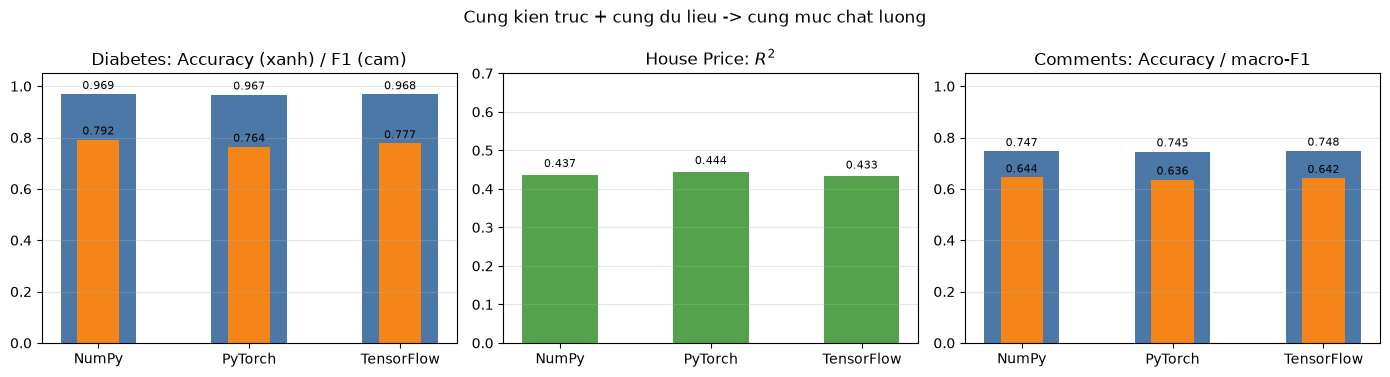

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
x = np.arange(3)
labels = ["NumPy", "PyTorch", "TensorFlow"]

axes[0].bar(x, df_dia["Accuracy"], color="#4C78A8", width=.5)
axes[0].bar(x, df_dia["F1"], color="#F58518", width=.28)
axes[0].set_xticks(x, labels); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Diabetes: Accuracy (xanh) / F1 (cam)")
for i, (a, f) in enumerate(zip(df_dia["Accuracy"], df_dia["F1"])):
    axes[0].text(i, a + .02, f"{a:.3f}", ha="center", fontsize=8)
    axes[0].text(i, f + .02, f"{f:.3f}", ha="center", fontsize=8)

axes[1].bar(x, df_hou["R2"], color="#54A24B", width=.5)
axes[1].set_xticks(x, labels); axes[1].set_ylim(0, 0.7)
axes[1].set_title("House Price: $R^2$")
for i, v in enumerate(df_hou["R2"]):
    axes[1].text(i, v + .02, f"{v:.3f}", ha="center", fontsize=8)

axes[2].bar(x, df_com["Accuracy"], color="#4C78A8", width=.5)
axes[2].bar(x, df_com["MacroF1"], color="#F58518", width=.28)
axes[2].set_xticks(x, labels); axes[2].set_ylim(0, 1.05)
axes[2].set_title("Comments: Accuracy / macro-F1")
for i, (a, f) in enumerate(zip(df_com["Accuracy"], df_com["MacroF1"])):
    axes[2].text(i, a + .02, f"{a:.3f}", ha="center", fontsize=8)
    axes[2].text(i, f + .02, f"{f:.3f}", ha="center", fontsize=8)

for ax in axes:
    ax.grid(alpha=.3, axis="y")
fig.suptitle("Cung kien truc + cung du lieu -> cung muc chat luong")
fig.tight_layout(); fig.savefig(RES / "fig_quality.png", dpi=140); plt.show()

## 5. Thời gian huấn luyện: đây mới là chỗ khác biệt

,Diabetes (30 ep),House Price (40 ep),Comments (4 ep)
NumPy from scratch,36.6,152.1,257.7
PyTorch,68.0,68.1,13.9
TensorFlow,45.7,50.6,15.1


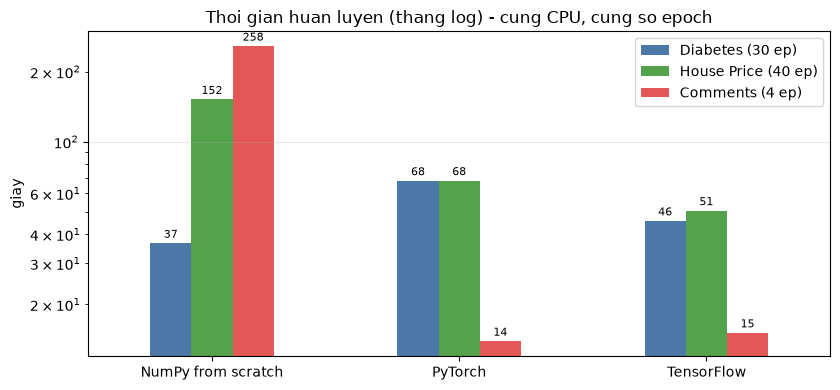

So lan nhanh hon ban from-scratch:


,Diabetes (30 ep),House Price (40 ep),Comments (4 ep)
PyTorch,0.54,2.23,18.54
TensorFlow,0.80,3.01,17.07


In [6]:
t = pd.DataFrame({
    "Diabetes (30 ep)": [records[(f, "diabetes")]["seconds"] for f in FW],
    "House Price (40 ep)": [records[(f, "housing")]["seconds"] for f in FW],
    "Comments (4 ep)": [records[(f, "comments")]["seconds"] for f in FW],
}, index=[FW_LABEL[f] for f in FW]).round(1)
display(t)

fig, ax = plt.subplots(figsize=(8.5, 4))
t.plot(kind="bar", ax=ax, rot=0, color=["#4C78A8", "#54A24B", "#E45756"])
ax.set_ylabel("giay"); ax.set_yscale("log")
ax.set_title("Thoi gian huan luyen (thang log) - cung CPU, cung so epoch")
ax.grid(alpha=.3, axis="y")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
fig.tight_layout(); fig.savefig(RES / "fig_time.png", dpi=140); plt.show()

speedup = (t.loc["NumPy from scratch"] / t.loc[["PyTorch", "TensorFlow"]]).round(2)
print("So lan nhanh hon ban from-scratch:")
display(speedup)

## 6. Đường học ba cài đặt vẽ chung

Nếu ba cài đặt thực sự cùng một mô hình toán học thì đường loss phải **chồng lên nhau**
(sai khác chỉ do khởi tạo và thứ tự minibatch).

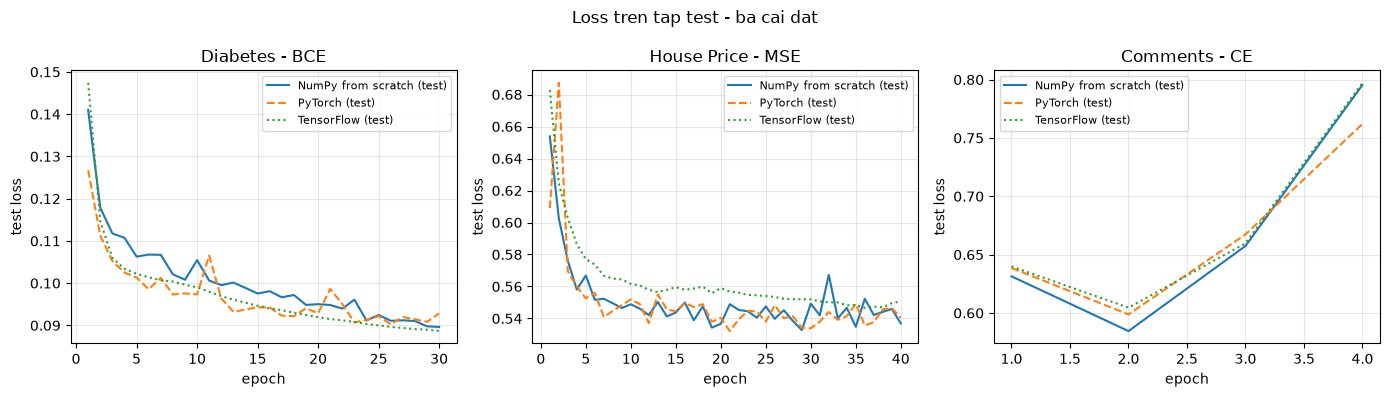

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, ds, title in zip(axes, ["diabetes", "housing", "comments"],
                         ["Diabetes - BCE", "House Price - MSE", "Comments - CE"]):
    for fw, style in zip(FW, ["-", "--", ":"]):
        h = records[(fw, ds)]["history"]
        ax.plot(h["epoch"], h["val_loss"], style, label=f"{FW_LABEL[fw]} (test)")
    ax.set_xlabel("epoch"); ax.set_ylabel("test loss"); ax.set_title(title)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.suptitle("Loss tren tap test - ba cai dat")
fig.tight_layout(); fig.savefig(RES / "fig_losscurves.png", dpi=140); plt.show()

## 7. Bảng tổng hợp cuối cùng

In [8]:
summary = []
for fw in FW:
    d, h, c = (records[(fw, k)] for k in ("diabetes", "housing", "comments"))
    summary.append(dict(
        Framework=FW_LABEL[fw],
        Dia_Acc=round(d["metrics"]["accuracy"], 4),
        Dia_F1=round(d["metrics"]["f1"], 4),
        Hou_MAE=round(h["metrics"]["mae"], 3),
        Hou_R2=round(h["metrics"]["r2"], 4),
        Com_Acc=round(c["metrics"]["accuracy"], 4),
        Com_MacroF1=round(c["metrics"]["macro_f1"], 4),
        Tong_giay=round(d["seconds"] + h["seconds"] + c["seconds"], 1),
    ))
df_all = pd.DataFrame(summary)
display(df_all)

df_all.to_csv(RES / "summary.csv", index=False)
with open(RES / "summary.md", "w", encoding="utf-8") as f:
    f.write("## Diabetes\n\n" + df_dia.round(4).to_markdown(index=False))
    f.write("\n\n## House Price (ty VND)\n\n" + df_hou.round(4).to_markdown(index=False))
    f.write("\n\n## Comments\n\n" + df_com.round(4).to_markdown(index=False))
    f.write("\n\n## Thoi gian (giay)\n\n" + t.to_markdown())
    f.write("\n\n## Tong hop\n\n" + df_all.to_markdown(index=False) + "\n")
print("Da ghi results/summary.csv va results/summary.md")

,Framework,Dia_Acc,Dia_F1,Hou_MAE,Hou_R2,Com_Acc,Com_MacroF1,Tong_giay
0,NumPy from scratch,0.9690,0.7919,1.312,0.4367,0.7467,0.6444,446.4
1,PyTorch,0.9667,0.7638,1.306,0.4444,0.7454,0.6359,150.0
2,TensorFlow,0.9680,0.7770,1.321,0.4327,0.7484,0.6421,111.4


Da ghi results/summary.csv va results/summary.md


## 8. Kết luận

**What stays the same** — dữ liệu, split, tiền xử lý, kiến trúc
(`Conv1D → ReLU → Conv1D → ReLU → Pool → Flatten → Dense`), hàm mất mát, metric,
và **chất lượng dự đoán**. Ba cột `Dia_Acc`, `Hou_R2`, `Com_Acc` ở bảng trên nằm
trong khoảng sai khác rất nhỏ giữa ba framework.

**What changes** — chỉ là tầng cài đặt:

| | NumPy | PyTorch | TensorFlow |
|---|---|---|---|
| Convolution | im2col + einsum tự viết | `nn.Conv1d` | `layers.Conv1D` |
| Layout tensor | `(N, C, L)` | `(N, C, L)` | `(N, L, C)` |
| Gradient | 3 công thức viết tay | `loss.backward()` | `GradientTape` |
| Cập nhật | Adam tự viết | `optim.Adam` | `keras.optimizers.Adam` |
| Vòng lặp | tự viết đầy đủ | tự viết | `fit()` |
| Dòng code cho một model | ~250 | ~20 | ~12 |

**Về bài toán:** CNN 1D đạt kết quả tốt nhất trên *Comments* — dữ liệu duy nhất có
tính cục bộ thật sự. Trên hai bộ tabular, convolution chỉ trộn các cột cạnh nhau
trong file CSV, một quan hệ **không có ý nghĩa ngữ nghĩa**, nên CNN không có lợi thế
nào so với một mạng dense cùng kích thước.